In [ ]:
!pip install -q -U "transformers>=5.17" accelerate bitsandbytes pillow
!pip install -q -U git+https://github.com/huggingface/diffusers
!python -c "import diffusers; from diffusers import QwenImage21Pipeline; print(diffusers.__version__, 'ok')"

In [1]:
import os
os.environ["HF_HOME"] = "/tmp/hf"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import gc, torch
from diffusers import AutoModel, QwenImage21Pipeline, BitsAndBytesConfig as DiffBnb
from transformers import Qwen3VLForConditionalGeneration, BitsAndBytesConfig as TfBnb

repo = "Qwen/Qwen-Image-2.1"
cfg = dict(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16)

transformer = AutoModel.from_pretrained(
    repo, subfolder="transformer",
    quantization_config=DiffBnb(**cfg), torch_dtype=torch.bfloat16,
)
text_encoder = Qwen3VLForConditionalGeneration.from_pretrained(
    repo, subfolder="text_encoder",
    quantization_config=TfBnb(**cfg), torch_dtype=torch.bfloat16,
    device_map={"": 1},
)

pipe = QwenImage21Pipeline.from_pretrained(
    repo, transformer=transformer, text_encoder=text_encoder,
    torch_dtype=torch.bfloat16,
)
pipe.vae.to("cuda:0")
pipe.vae.enable_tiling()

main, te_dev = torch.device("cuda:0"), torch.device("cuda:1")
pipe.__class__ = type("SplitPipe", (pipe.__class__,), {
    "device": property(lambda self: main),
    "_execution_device": property(lambda self: main),
})

def move(x, dev):
    if torch.is_tensor(x):
        return x.to(dev)
    if isinstance(x, dict):
        for k in list(x.keys()):
            x[k] = move(x[k], dev)
        return x
    if isinstance(x, (list, tuple)):
        return type(x)(move(v, dev) for v in x)
    return x

pipe.text_encoder.register_forward_pre_hook(
    lambda m, a, k: (move(a, te_dev), move(k, te_dev)), with_kwargs=True)
pipe.text_encoder.register_forward_hook(
    lambda m, a, k, out: move(out, main), with_kwargs=True)

print([round(torch.cuda.memory_allocated(i) / 1e9, 1) for i in (0, 1)])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/447 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/370 [00:00<?, ?B/s]

(…)ion_pytorch_model.safetensors.index.json:   0%|          | 0.00/30.3k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

[4.7, 6.7]


In [2]:
import numpy as np
from PIL import Image

size = 512
image = Image.open("/kaggle/input/datasets/shahdelsawy/living-room/download.jpg").convert("RGB")
s = size / max(image.size)
W, H = round(image.width * s / 32) * 32, round(image.height * s / 32) * 32
image = image.resize((W, H))

for i in (0, 1):
    torch.cuda.reset_peak_memory_stats(i)
result = pipe(
    prompt=("Replace the sofa with a dark green velvet sofa. "
            "Keep the room, lighting, and everything else unchanged."),
    image=image, width=W, height=H,
    num_inference_steps=30,
    generator=torch.Generator("cpu").manual_seed(42),
).images[0]
print([round(torch.cuda.max_memory_allocated(i) / 1e9, 1) for i in (0, 1)])

Image.fromarray(np.hstack([np.array(image), np.array(result.resize(image.size))]))

  0%|          | 0/30 [00:00<?, ?it/s]

[12.3, 9.6]


ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 2, the array at index 0 has size 3 and the array at index 1 has size 4

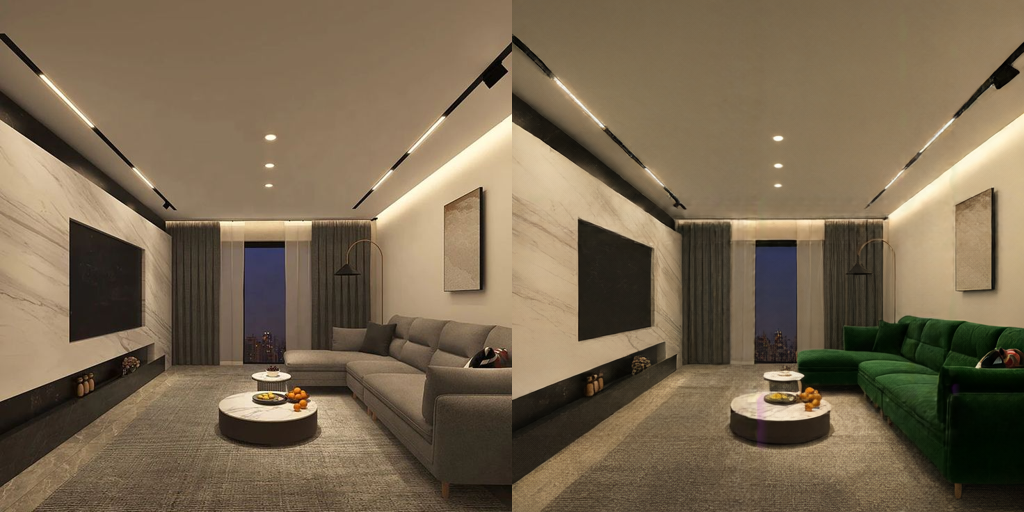

In [3]:
out = result.convert("RGB").resize(image.size)
out.save("edited.png")
Image.fromarray(np.hstack([np.array(image), np.array(out)]))

In [5]:
size = 512
image2 = Image.open("/kaggle/input/datasets/shahdelsawy/living-room/download (1).jpg").convert("RGB")
s = size / max(image2.size)
W, H = round(image2.width * s / 32) * 32, round(image2.height * s / 32) * 32
image2 = image2.resize((W, H))

for i in (0, 1):
    torch.cuda.reset_peak_memory_stats(i)
result2 = pipe(
    prompt=("Replace the Painting on the Wall With A colorfull Painting. "
            "Keep the room, lighting, and everything else unchanged."),
    image=image2, width=W, height=H,
    num_inference_steps=30,
    generator=torch.Generator("cpu").manual_seed(42),
).images[0]
print([round(torch.cuda.max_memory_allocated(i) / 1e9, 1) for i in (0, 1)])

Image.fromarray(np.hstack([np.array(image2), np.array(result2.resize(image2.size))]))


  0%|          | 0/30 [00:00<?, ?it/s]

[12.6, 9.8]


ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 2, the array at index 0 has size 3 and the array at index 1 has size 4

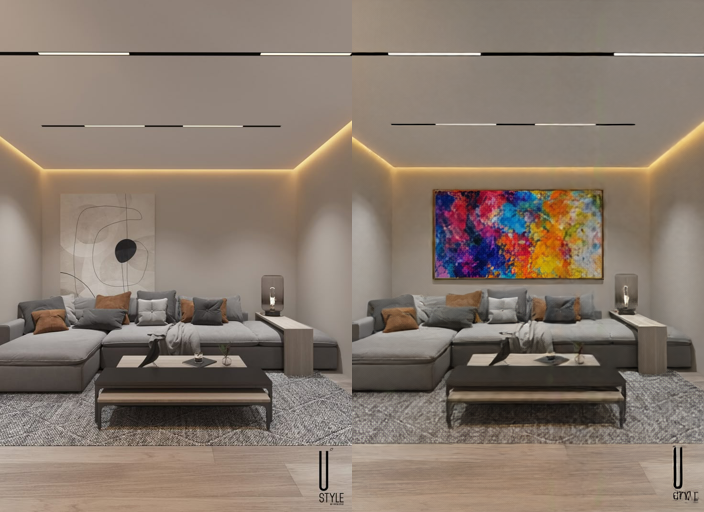

In [6]:
out = result2.convert("RGB").resize(image2.size)
out.save("edited.png")
Image.fromarray(np.hstack([np.array(image2), np.array(out)]))